In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# --- ЭТАП 1: Создание данных и заполнение пропусков ---

data = {
    'CustomerID': list(range(1, 61)),
    'Age': [25, np.nan, 35, 45, np.nan, 55, 65, 25, 35, 45] * 6,
    'AveragePurchaseValue': [100, 200, 300, np.nan, 400, 500, 600, np.nan, 700, 800] * 6,
    'PurchaseFrequency': [1, 2, 3, 4, 5, np.nan] * 10
}

df = pd.DataFrame(data)


df

,CustomerID,Age,AveragePurchaseValue,PurchaseFrequency
0,1,25.0,100.0,1.0
1,2,NaN,200.0,2.0
2,3,35.0,300.0,3.0
3,4,45.0,NaN,4.0
4,5,NaN,400.0,5.0
5,6,55.0,500.0,NaN
6,7,65.0,600.0,1.0
7,8,25.0,NaN,2.0
8,9,35.0,700.0,3.0
9,10,45.0,800.0,4.0


In [20]:
# Заполняем пропуски медианами и средним
df['AveragePurchaseValue'] = df['AveragePurchaseValue'].fillna(df['AveragePurchaseValue'].median())
df['PurchaseFrequency'] = df['PurchaseFrequency'].fillna(df['PurchaseFrequency'].median())
df['Age'] = df['Age'].fillna(df['Age'].mean())
df

,CustomerID,Age,AveragePurchaseValue,PurchaseFrequency
0,1,25.00,100.0,1.0
1,2,41.25,200.0,2.0
2,3,35.00,300.0,3.0
3,4,45.00,450.0,4.0
4,5,41.25,400.0,5.0
5,6,55.00,500.0,3.0
6,7,65.00,600.0,1.0
7,8,25.00,450.0,2.0
8,9,35.00,700.0,3.0
9,10,45.00,800.0,4.0


In [ ]:
# --- ЭТАП 2: Подготовка данных к кластеризации ---
# Выбираем только числовые признаки для анализа (исключаем CustomerID)
features = ['Age', 'AveragePurchaseValue', 'PurchaseFrequency']
X = df[features]

# Нормализуем данные, чтобы все признаки имели одинаковый вес
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- ЭТАП 3: Метод локтя (поиск оптимального количества кластеров K) ---
inertia = []
K_range = range(1, 7)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

print(inertia) #Значения инерции при различных показателях в группах K

[180.0, 118.04819360176504, 95.97614744614742, 78.91958386958387, 71.11967967967968, 63.7511583011583]


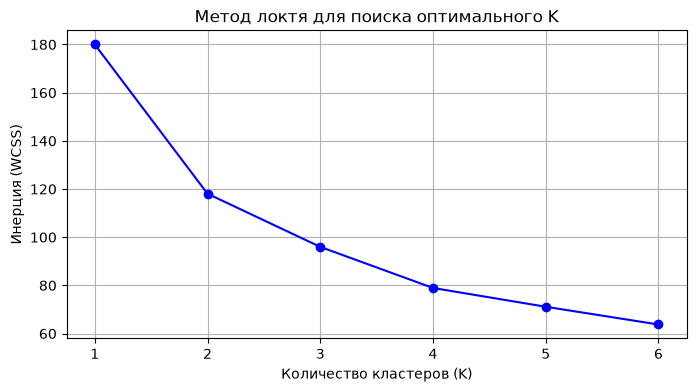

In [24]:
# Рисуем график
plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker='o', color='b')
plt.title('Метод локтя для поиска оптимального K')
plt.xlabel('Количество кластеров (K)')
plt.ylabel('Инерция (WCSS)')
plt.grid(True)
plt.show()

In [ ]:

# --- ЭТАП 4: Кластеризация (берем K = 3) ---
optimal_k = 3 #Т.к. это хорошее "промежуточное значение", после которого иннерция не сильно меняется.
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init='auto')
df['Cluster'] = kmeans.fit_predict(X_scaled)  
# разметили клиентов по кластерам

print("Средние показатели клиентов по кластерам:")
df.groupby('Cluster')[features].mean().round(2)

Средние показатели клиентов по кластерам:


,Age,AveragePurchaseValue,PurchaseFrequency
Cluster,,,
0,32.64,277.78,3.89
1,41.25,413.64,1.73
2,49.00,645.00,3.60


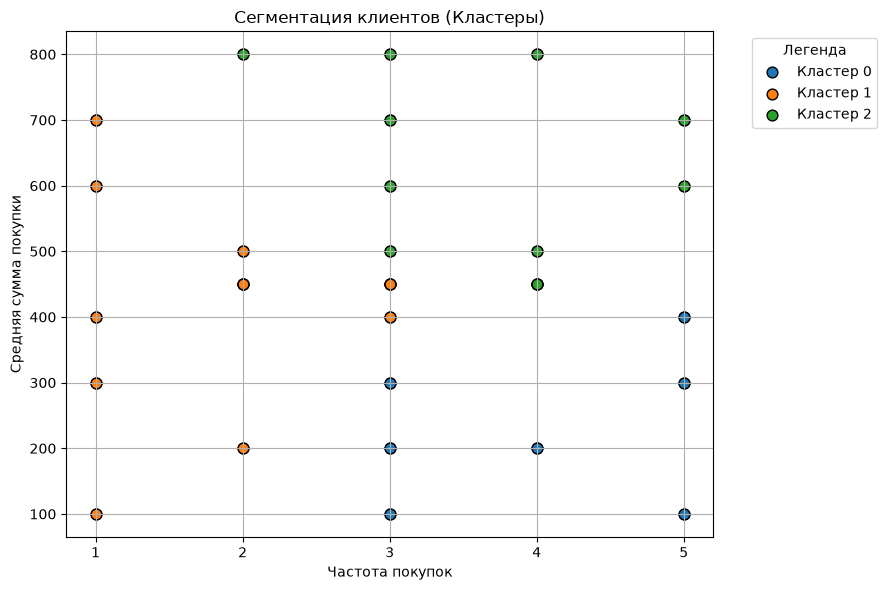

In [39]:
# --- ЭТАП 5: Визуализация результатов с легендой вне графика ---
plt.figure(figsize=(9, 6))  # Слегка расширим холст по ширине для легенды

for cluster_id in sorted(df['Cluster'].unique()):
    cluster_data = df[df['Cluster'] == cluster_id]
    
    plt.scatter(
        cluster_data['PurchaseFrequency'], 
        cluster_data['AveragePurchaseValue'], 
        label=f'Кластер {cluster_id}', 
        s=60, 
        edgecolor='k'
    )

plt.title('Сегментация клиентов (Кластеры)')
plt.xlabel('Частота покупок')
plt.ylabel('Средняя сумма покупки')
plt.locator_params(axis='x', integer=True)

plt.grid(True)

# Выносим легенду вправо за пределы графика
plt.legend(title='Легенда', bbox_to_anchor=(1.05, 1), loc='upper left')

# Автоматически настраиваем отступы, чтобы текст не обрезался
plt.tight_layout()
plt.show()

In [59]:
# Считаем количество клиентов и средний возраст по кластерам
cluster_stats = df.groupby('Cluster').agg(
    CustomerCount=('CustomerID', 'count'),  # Количество клиентов в кластере
    AverageAge=('Age', 'mean'),              # Средний возраст в кластере
    AveragePurchase = ('AveragePurchaseValue', 'mean'),
    PurchaseFrequency = ('PurchaseFrequency', 'count')
    )

cluster_stats.round(2)

,CustomerCount,AverageAge,AveragePurchase,PurchaseFrequency
Cluster,,,,
0,18,32.64,277.78,18
1,22,41.25,413.64,22
2,20,49.00,645.00,20


 Описание задачи:

Вы работаете аналитиком данных в интернет-магазине. Компания хочет перейти от массовых рекламных рассылок к персонализированным маркетинговым кампаниям. Предполагается, что клиенты магазина отличаются по своему покупательскому поведению, однако заранее неизвестно, сколько существует групп клиентов и чем они характеризуются.

Ваша задача — самостоятельно выявить группы клиентов на основе их покупательского поведения с помощью алгоритма K-средних, проанализировать особенности полученных кластеров и предложить рекомендации по работе с каждой группой. Для выполнения задания необходимо сформировать собственный набор данных о клиентах интернет-магазина.

## Ответ

*Разработайте рекомендации по персонализированным маркетинговым стратегиям для выделенных групп клиентов*:

**Для Кластера 2** возможно стоит ввести программу лояльности, либо промо-акции, чтобы увеличить частоту покупок. Т.к. видно, что аудитория этого кластера более взрослая и у неё наиболее высокий средний чек. Но частота у большинства покупателей из этого кластера на уровне кластера 0, у которой достаточно низкий средний чек.

**Кластер 1** = возможно, промо-материалы работают на привлечение этой аудитории, но Retention Rate (метрика возвращения клиента к продукту) низкая. Т.е. буквально 1-2 покупки, после чего основная часть этого кластера уходит.

**Кластер 0** = наиболее активный (и молодой) кластер покупателей. Средний чек низкий, но частота покупок самая высокая. Возможно эта аудитория уже знает про промо-материалы, рекламные акции и т.д.

*Сформулируйте итоговые выводы по результатам исследования*:

Возможно, стоит расширить ассортимент товаров (посмотреть что покупают люди из Кластера 2 и Кластера 0). Если увеличить вовлечённость Кластера 2 в продукт, то это может увеличить частоту покупок. А у Кластера 0 увеличить средний чек

Почтовая рассылка/пуш-уведомления могут помочь с возвращением Кластера 1 к продукту.
